In [1]:
!pip install -q datasets scikit-learn
from datasets import load_dataset
ds = load_dataset("fancyzhx/ag_news")
print(ds)

DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})


In [2]:
import pandas as pd
names = ["World", "Sports", "Business", "Sci/Tech"]
train_df = ds["train"].to_pandas()
test_df = ds["test"].to_pandas()

print(train_df["label"].map(dict(enumerate(names))).value_counts())
for i in range(5):
    print(names[train_df.label[i]], "|", train_df.text[i][:120])

label
Business    30000
Sci/Tech    30000
Sports      30000
World       30000
Name: count, dtype: int64
Business | Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics,
Business | Carlyle Looks Toward Commercial Aerospace (Reuters) Reuters - Private investment firm Carlyle Group,\which has a reputat
Business | Oil and Economy Cloud Stocks' Outlook (Reuters) Reuters - Soaring crude prices plus worries\about the economy and the ou
Business | Iraq Halts Oil Exports from Main Southern Pipeline (Reuters) Reuters - Authorities have halted oil export\flows from the
Business | Oil prices soar to all-time record, posing new menace to US economy (AFP) AFP - Tearaway world oil prices, toppling reco


In [3]:
from sklearn.model_selection import train_test_split

tr_idx, va_idx = train_test_split(
    range(len(train_df)), test_size=0.10, stratify=train_df["label"], random_state=42)

tr = train_df.iloc[tr_idx].reset_index(drop=True)
va = train_df.iloc[va_idx].reset_index(drop=True)
te = test_df

print(len(tr), len(va), len(te))
print("duplicate texts inside train:", tr.text.duplicated().sum())
print("val texts also in train:", va.text.isin(tr.text).sum())
print("test texts also in train:", te.text.isin(tr.text).sum())

108000 12000 7600
duplicate texts inside train: 0
val texts also in train: 0
test texts also in train: 0


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score

vec = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_features=200000)
X_tr = vec.fit_transform(tr.text)
X_va = vec.transform(va.text)

clf = LogisticRegression(max_iter=1000)
clf.fit(X_tr, tr.label)

pred = clf.predict(X_va)
print("val accuracy:", accuracy_score(va.label, pred))
print("val macro F1:", f1_score(va.label, pred, average="macro"))

val accuracy: 0.9224166666666667
val macro F1: 0.9222053402617887


In [5]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(va.label, pred, target_names=names, digits=3))

cm = confusion_matrix(va.label, pred)
print(pd.DataFrame(cm, index=[f"true {n}" for n in names], columns=[f"pred {n}" for n in names]))

pairs = [(cm[i, j], names[i], names[j]) for i in range(4) for j in range(4) if i != j]
for n, t, p in sorted(pairs, reverse=True)[:5]:
    print(f"{n:4d}  true {t} -> predicted {p}")

              precision    recall  f1-score   support

       World      0.931     0.907     0.919      3000
      Sports      0.952     0.981     0.967      3000
    Business      0.901     0.888     0.894      3000
    Sci/Tech      0.905     0.913     0.909      3000

    accuracy                          0.922     12000
   macro avg      0.922     0.922     0.922     12000
weighted avg      0.922     0.922     0.922     12000

               pred World  pred Sports  pred Business  pred Sci/Tech
true World           2720           90            113             77
true Sports            27         2944             17             12
true Business         105           30           2665            200
true Sci/Tech          69           27            164           2740
 200  true Business -> predicted Sci/Tech
 164  true Sci/Tech -> predicted Business
 113  true World -> predicted Business
 105  true Business -> predicted World
  90  true World -> predicted Sports


In [6]:
wrong = np.where(va.label.values != pred)[0]
rng = np.random.RandomState(0)
for i in rng.choice(wrong, 15, replace=False):
    print(f"true: {names[va.label[i]]:9s} pred: {names[pred[i]]:9s} | {va.text[i][:150]}")
    print()

true: Business  pred: Sports    | 3 things you must know to be successful A dozen years ago I asked a friend of mine if he would share with me a technical indicator he had invented. He

true: Sci/Tech  pred: Business  | SCO caps legal costs as losses mount The SCO Group is looking to cut expenses to make sure it has enough cash to push its lawsuit with IBM, the compan

true: World     pred: Business  | Brown tells activists to return to party values Gordon Brown will make an appeal today to traditional Labour values, calling on rank and file to build

true: World     pred: Sci/Tech  | SpaceShipOne takes X-Prize spoils TheSpaceShipOne team is handed the \$10m cheque and trophy it won for claiming the Ansari X-Prize.

true: Sports    pred: World     | Accreditation Team Criticizes U. of Ill. (AP) AP - A panel from the association that accredits the University of Illinois chastised the school Wednesd

true: Sci/Tech  pred: World     | Supreme Court to Hear ISP, Cable Dispute (AP) AP - The

In [7]:
import torch
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print(torch.cuda.get_device_name(0))
!pip install -q -U transformers accelerate

GPU available: True
Tesla T4


In [8]:
sub = tr.groupby("label", group_keys=False).sample(n=5000, random_state=42).reset_index(drop=True)
print(len(sub), sub.label.value_counts().to_dict())

vec_s = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_features=200000)
X_sub = vec_s.fit_transform(sub.text)
X_va_s = vec_s.transform(va.text)

clf_s = LogisticRegression(max_iter=1000)
clf_s.fit(X_sub, sub.label)

pred_s = clf_s.predict(va.text.pipe(vec_s.transform))
print("val accuracy (20k):", accuracy_score(va.label, pred_s))
print("val macro F1 (20k):", f1_score(va.label, pred_s, average="macro"))

20000 {0: 5000, 1: 5000, 2: 5000, 3: 5000}
val accuracy (20k): 0.9034166666666666
val macro F1 (20k): 0.9030683641361784


In [9]:
import torch, numpy as np
from torch.utils.data import TensorDataset, DataLoader
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("distilbert-base-uncased")

def encode(texts, labels):
    e = tok(list(texts), truncation=True, padding="max_length", max_length=64, return_tensors="pt")
    return TensorDataset(e["input_ids"], e["attention_mask"], torch.tensor(list(labels)))

train_ds = encode(sub.text, sub.label)
val_ds = encode(va.text, va.label)
train_dl = DataLoader(train_ds, batch_size=32, shuffle=True)
val_dl = DataLoader(val_ds, batch_size=128)

print(len(train_ds), len(val_ds))
print(tok.convert_ids_to_tokens(train_ds[0][0][:20]))

20000 12000
['[CLS]', 'spain', 'bust', '##s', 'a', 'suspected', 'muslim', 'terror', 'ring', 'eight', 'muslim', 'terrorists', 'planning', 'to', 'det', '##onate', 'a', '1', ',', '100']


In [10]:
from transformers import AutoModelForSequenceClassification
from sklearn.metrics import accuracy_score, f1_score

torch.manual_seed(42)
device = "cuda"

model = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=4).to(device)
opt = torch.optim.AdamW(model.parameters(), lr=3e-5, weight_decay=0.01)

def evaluate(dl):
    model.eval()
    ps, ys = [], []
    with torch.no_grad():
        for ids, mask, y in dl:
            out = model(input_ids=ids.to(device), attention_mask=mask.to(device))
            ps += out.logits.argmax(1).cpu().tolist()
            ys += y.tolist()
    return np.array(ys), np.array(ps)

best_f1, best_state = 0, None
for epoch in range(2):
    model.train()
    total = 0
    for ids, mask, y in train_dl:
        out = model(input_ids=ids.to(device), attention_mask=mask.to(device), labels=y.to(device))
        opt.zero_grad()
        out.loss.backward()
        opt.step()
        total += out.loss.item()
    ys, ps = evaluate(val_dl)
    acc, f1 = accuracy_score(ys, ps), f1_score(ys, ps, average="macro")
    print(f"epoch {epoch+1}: train loss {total/len(train_dl):.3f} | val acc {acc:.4f} | val macro F1 {f1:.4f}")
    if f1 > best_f1:
        best_f1 = f1
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


epoch 1: train loss 0.315 | val acc 0.9211 | val macro F1 0.9207
epoch 2: train loss 0.171 | val acc 0.9255 | val macro F1 0.9252


In [11]:
model.load_state_dict(best_state)
ys, ps = evaluate(val_dl)

print(classification_report(ys, ps, target_names=names, digits=3))

cm_b = confusion_matrix(ys, ps)
print(pd.DataFrame(cm_b, index=[f"true {n}" for n in names], columns=[f"pred {n}" for n in names]))

pairs = [(cm_b[i, j], names[i], names[j]) for i in range(4) for j in range(4) if i != j]
for n, t, p in sorted(pairs, reverse=True)[:5]:
    print(f"{n:4d}  true {t} -> predicted {p}")

              precision    recall  f1-score   support

       World      0.958     0.904     0.930      3000
      Sports      0.952     0.993     0.972      3000
    Business      0.908     0.874     0.890      3000
    Sci/Tech      0.887     0.930     0.908      3000

    accuracy                          0.925     12000
   macro avg      0.926     0.925     0.925     12000
weighted avg      0.926     0.925     0.925     12000

               pred World  pred Sports  pred Business  pred Sci/Tech
true World           2713           75            123             89
true Sports            11         2980              6              3
true Business          59           54           2622            265
true Sci/Tech          50           21            138           2791
 265  true Business -> predicted Sci/Tech
 138  true Sci/Tech -> predicted Business
 123  true World -> predicted Business
  89  true World -> predicted Sci/Tech
  75  true World -> predicted Sports


In [12]:
from sklearn.metrics import precision_recall_fscore_support

def per_class_f1(y, p):
    return precision_recall_fscore_support(y, p, labels=[0, 1, 2, 3], zero_division=0)[2]

table = pd.DataFrame({
    "TF-IDF 108k": per_class_f1(va.label, pred),
    "TF-IDF 20k": per_class_f1(va.label, pred_s),
    "DistilBERT 20k": per_class_f1(ys, ps),
}, index=names).round(3)
table.loc["macro avg"] = table.mean().round(3)
print(table)

# Business <-> Sci/Tech errors made by DistilBERT
bs = np.where((ys == 2) & (ps == 3))[0]
for i in np.random.RandomState(1).choice(bs, 10, replace=False):
    print(f"true Business, pred Sci/Tech | {va.text[i][:150]}")

           TF-IDF 108k  TF-IDF 20k  DistilBERT 20k
World            0.919       0.906           0.930
Sports           0.967       0.952           0.972
Business         0.894       0.872           0.890
Sci/Tech         0.909       0.882           0.908
macro avg        0.922       0.903           0.925
true Business, pred Sci/Tech | IBM Says Its Supercomputer Is World #39;s Fastest International Business Machines Corp. on Wednesday said it has developed the world #39;s fastest com
true Business, pred Sci/Tech | Caught in a regulatory cross fire Here's a bit of advice for those of you planning IT budgets. For the next five to 10 years, set aside 10 percent to 
true Business, pred Sci/Tech | Virgin Mobile adds more customers Virgin Mobile added 647,000 new users in the last half-year with turnover up by 18, the firm says, but profits fell 
true Business, pred Sci/Tech | Space-age sport  GPS is invading recreational sports. Under clear skies, those signals beaming to earth from satellit

In [13]:
# TF-IDF models
for name, v, c in [("TF-IDF 108k", vec, clf), ("TF-IDF 20k", vec_s, clf_s)]:
    p = c.predict(v.transform(te.text))
    print(f"{name}: test acc {accuracy_score(te.label, p):.4f} | macro F1 {f1_score(te.label, p, average='macro'):.4f}")

# DistilBERT (best_state is already loaded from Cell 11)
test_dl = DataLoader(encode(te.text, te.label), batch_size=128)
yt, pt = evaluate(test_dl)
print(f"DistilBERT 20k: test acc {accuracy_score(yt, pt):.4f} | macro F1 {f1_score(yt, pt, average='macro'):.4f}")

TF-IDF 108k: test acc 0.9182 | macro F1 0.9179
TF-IDF 20k: test acc 0.8975 | macro F1 0.8971
DistilBERT 20k: test acc 0.9225 | macro F1 0.9223


In [ ]:
def sample_n(n, seed):
    return tr.groupby("label", group_keys=False).sample(n=n // 4, random_state=seed).reset_index(drop=True)

def tfidf_f1(s):
    v = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=2, max_features=200000)
    c = LogisticRegression(max_iter=1000).fit(v.fit_transform(s.text), s.label)
    return f1_score(va.label, c.predict(v.transform(va.text)), average="macro")

def distil_f1(s, epochs, seed):
    torch.manual_seed(seed)
    m = AutoModelForSequenceClassification.from_pretrained("distilbert-base-uncased", num_labels=4).to(device)
    o = torch.optim.AdamW(m.parameters(), lr=3e-5, weight_decay=0.01)
    dl = DataLoader(encode(s.text, s.label), batch_size=32, shuffle=True)
    for _ in range(epochs):
        m.train()
        for ids, mask, y in dl:
            out = m(input_ids=ids.to(device), attention_mask=mask.to(device), labels=y.to(device))
            o.zero_grad(); out.loss.backward(); o.step()
    m.eval(); p = []
    with torch.no_grad():
        for ids, mask, y in val_dl:
            p += m(input_ids=ids.to(device), attention_mask=mask.to(device)).logits.argmax(1).cpu().tolist()
    del m, o
    torch.cuda.empty_cache()
    return f1_score(va.label, p, average="macro")

plan = {100: 10, 500: 5, 2000: 3, 10000: 2}   # training size: epochs
rows = []
for n, ep in plan.items():
    seeds = [42, 43, 44] if n <= 2000 else [42]
    t = np.mean([tfidf_f1(sample_n(n, s)) for s in seeds])
    d = np.mean([distil_f1(sample_n(n, s), ep, s) for s in seeds])
    rows.append((n, ep, len(seeds), round(t, 3), round(d, 3)))
    print(rows[-1])

print(pd.DataFrame(rows, columns=["train size", "epochs", "seeds", "TF-IDF F1", "DistilBERT F1"]))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


... (13 outputs left out)

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


(2000, 3, 3, np.float64(0.857), np.float64(0.883))


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


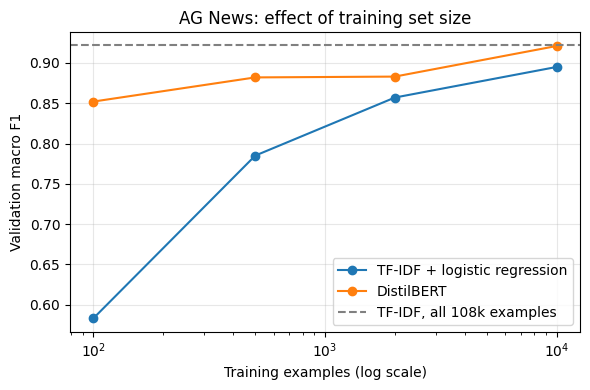

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
import matplotlib.pyplot as plt
from google.colab import files

df = pd.DataFrame(rows, columns=["train size", "epochs", "seeds", "TF-IDF F1", "DistilBERT F1"])

plt.figure(figsize=(6, 4))
plt.plot(df["train size"], df["TF-IDF F1"], marker="o", label="TF-IDF + logistic regression")
plt.plot(df["train size"], df["DistilBERT F1"], marker="o", label="DistilBERT")
plt.axhline(0.922, linestyle="--", color="gray", label="TF-IDF, all 108k examples")
plt.xscale("log")
plt.xlabel("Training examples (log scale)")
plt.ylabel("Validation macro F1")
plt.title("AG News: effect of training set size")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("learning_curve.png", dpi=150)
plt.show()
files.download("learning_curve.png")

In [18]:
import random

def add_typos(text, p, seed):
    rnd = random.Random(seed)
    out = []
    for w in text.split(" "):
        if len(w) > 3 and w.isalpha() and rnd.random() < p:
            i = rnd.randrange(1, len(w) - 2)          # keep first and last letter
            w = w[:i] + w[i + 1] + w[i] + w[i + 2:]   # swap two neighbouring letters
        out.append(w)
    return " ".join(out)

print(add_typos(va.text[0], 0.3, 0))
print(va.text[0])

results = {"model": [], "clean": [], "typos 15%": [], "typos 30%": []}
levels = {"clean": 0.0, "typos 15%": 0.15, "typos 30%": 0.30}
noisy = {k: [add_typos(t, p, 42) for t in va.text] for k, p in levels.items()}

def f1_tfidf(v, c, texts):
    return f1_score(va.label, c.predict(v.transform(texts)), average="macro")

def f1_bert(texts):
    y, p = evaluate(DataLoader(encode(texts, va.label), batch_size=128))
    return f1_score(y, p, average="macro")

for name, fn in [("TF-IDF 108k", lambda t: f1_tfidf(vec, clf, t)),
                 ("TF-IDF 20k", lambda t: f1_tfidf(vec_s, clf_s, t)),
                 ("DistilBERT 20k", f1_bert)]:
    results["model"].append(name)
    for k in levels:
        results[k].append(round(fn(noisy[k]), 4))

res = pd.DataFrame(results)
res["drop at 15%"] = (res["clean"] - res["typos 15%"]).round(4)
res["drop at 30%"] = (res["clean"] - res["typos 30%"]).round(4)
print(res)

Orange Unveils 3G Phones in Long-Delayed Laucnh  LONDON/PARIS (Reuters) - Orange unveiled its  third-generation (3G) mobile phones in a long-delayed  commercial launch, with sveen new hnadset models amied at its  key French market and at least four at Britain in tmie for  Christmas.
Orange Unveils 3G Phones in Long-Delayed Launch  LONDON/PARIS (Reuters) - Orange unveiled its  third-generation (3G) mobile phones in a long-delayed  commercial launch, with seven new handset models aimed at its  key French market and at least four at Britain in time for  Christmas.
            model   clean  typos 15%  typos 30%  drop at 15%  drop at 30%
0     TF-IDF 108k  0.9222     0.9121     0.9057       0.0101       0.0165
1      TF-IDF 20k  0.9031     0.8909     0.8845       0.0122       0.0186
2  DistilBERT 20k  0.9252     0.9022     0.8850       0.0230       0.0402
